# HW05 (c) - Coupled input matching and resonance

Retune L1 at every W1 candidate. Remove the external 50-ohm source branch for the input-impedance measurement and inject 1 A into VinNode. Inspect Rin, the retuned inductance and resonance together.

**Kernel: ECE6420 (Local).** Local **Run All** runs computation through SSH and renders plots here. Set `EXECUTION_MODE = "review"` in the setup cell to redraw saved data without SSH.

[Assignment](../references/HW5_LNA_sim_revised.pdf) | [Solution](../references/ECE6420_HW5_solution_Fall_2026.pdf)

The original IIP3 method is preserved. Its floating-point time-window boundary can omit a sample; the results include a separate coherent-window check. A single-point intercept still requires cubic-scaling validation.

In [1]:
from pathlib import Path
import sys
candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for base in candidates for p in (base, base / "HW05")
             if (p / "netlists" / "reference" / "input.scs").is_file()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook inside the Gatech-ECE6420 checkout.")
sys.path.insert(0, str(ROOT / "lib"))
from runtime import *
from remote_bridge import run_remote_parts
EXECUTION_MODE = execution_mode()  # Default: remote. Set "review" here to redraw saved data only.
RUN_SIMULATIONS = EXECUTION_MODE == "server"
if RUN_SIMULATIONS:
    preflight()
else:
    from plots import show_part, show_summary, spectrum
print("Kernel interpreter:", sys.executable)
print("Mode:", EXECUTION_MODE, "| project:", ROOT)


Kernel interpreter: /Library/Frameworks/Python.framework/Versions/3.12/bin/python3
Mode: review | project: /Users/jeonsang-eon/Gatech-ECE6420/HW05


## Parameters
These values are editable in this local kernel. The remote Run cell sends their current values to the server.

In [2]:
import math
import tune_c
TARGET_R = 50.0
F_TOL_MHZ = 2.0
R_TOL_OHM = 0.25


## Measurement helpers
Build analysis netlists from the trusted reference and parse actual Spectre ASCII traces.

In [3]:
def tune_l(w_um, guess_nh):
    lo = max(0.2, 0.78 * guess_nh)
    hi = 1.22 * guess_nh
    f_lo = tune_c.resonance(w_um, lo)
    f_hi = tune_c.resonance(w_um, hi)

    for _ in range(8):
        if f_lo >= F0:
            break
        hi, f_hi = lo, f_lo
        lo *= 0.65
        f_lo = tune_c.resonance(w_um, lo)

    for _ in range(8):
        if f_hi <= F0:
            break
        lo, f_lo = hi, f_hi
        hi *= 1.45
        f_hi = tune_c.resonance(w_um, hi)

    if not (f_lo >= F0 and f_hi <= F0):
        raise RuntimeError("Could not bracket 5.8-GHz resonance")

    best = None
    for _ in range(13):
        mid = 0.5 * (lo + hi)
        f_mid = tune_c.resonance(w_um, mid)
        err = abs(f_mid - F0)
        if best is None or err < best[0]:
            best = (err, mid, f_mid)
        if err <= F_TOL_MHZ * 1e6:
            break
        if f_mid > F0:
            lo = mid
        else:
            hi = mid
    return best[1], best[2]

def evaluate(w_um, l_guess):
    l_nh, fres = tune_l(w_um, l_guess)
    rin = tune_c.rin(w_um, l_nh)
    print(
        f"POINT W={w_um:.6f} um  L={l_nh:.6f} nH  "
        f"fres={fres/1e9:.6f} GHz  Rin={rin:.4f} ohm"
    )
    return (w_um, l_nh, fres, rin)


## Run and plot
Run this local cell to synchronize source, compute remotely, fetch numerical data, and render the plots immediately below. Current parameter-cell values are sent to the worker.

In [4]:
if EXECUTION_MODE == "remote":
    run_remote_parts("c", {"c": {name: globals()[name] for name in ['TARGET_R', 'F_TOL_MHZ', 'R_TOL_OHM']}})

    show_part("c")

## Server analysis
These cells execute in the server worker. A local Run delegates computation through the preceding SSH bridge; review mode uses saved numerical data.

In [5]:
if RUN_SIMULATIONS:
    meta = load_meta()
    b = require_part(meta, "b")
    bout = b["outputs"]

    w0 = float(bout["W1_um"])
    l0 = float(bout["L1_nH"])

    print("HW5(c): obtain Rin=50 ohm while re-tuning L1 to 5.8 GHz")
    print(f"Loaded part (b): W1={w0:.6f} um, L1={l0:.6f} nH")

    p0 = evaluate(w0, l0)
    points = [p0]

    if abs(p0[3] - TARGET_R) <= R_TOL_OHM:
        best = p0
    else:
        factor = 1.40
        pup = evaluate(w0 * factor, l0)
        pdn = evaluate(w0 / factor, l0)
        points.extend([pup, pdn])

        direction = min((pup, pdn), key=lambda p: abs(p[3] - TARGET_R))
        go_up = direction[0] > w0
        last = p0
        cur = direction
        bracket = None

        if (last[3] - TARGET_R) * (cur[3] - TARGET_R) <= 0:
            bracket = tuple(sorted((last, cur), key=lambda p: p[0]))

        for _ in range(14):
            if bracket is not None:
                break
            last = cur
            next_w = cur[0] * factor if go_up else cur[0] / factor
            if not (0.5 <= next_w <= 1000.0):
                break
            cur = evaluate(next_w, cur[1])
            points.append(cur)
            if (last[3] - TARGET_R) * (cur[3] - TARGET_R) <= 0:
                bracket = tuple(sorted((last, cur), key=lambda p: p[0]))

        if bracket is None:
            print("\nNo 50-ohm crossing found. Evaluated points:")
            for p in sorted(points, key=lambda p: p[0]):
                print(
                    f"W={p[0]:.6f} um, L={p[1]:.6f} nH, "
                    f"fres={p[2]/1e9:.6f} GHz, Rin={p[3]:.4f} ohm"
                )
            raise SystemExit(2)

        left, right = bracket
        wa, la, fa, ra = left
        wb, lb, fb, rb = right
        best = min((left, right), key=lambda p: abs(p[3] - TARGET_R))

        for _ in range(11):
            wm = 0.5 * (wa + wb)
            alpha = (wm - wa) / (wb - wa)
            l_guess = la + alpha * (lb - la)
            pm = evaluate(wm, l_guess)
            points.append(pm)

            if abs(pm[3] - TARGET_R) < abs(best[3] - TARGET_R):
                best = pm
            if abs(pm[3] - TARGET_R) <= R_TOL_OHM:
                break

            if (ra - TARGET_R) * (pm[3] - TARGET_R) <= 0:
                wb, lb, fb, rb = pm
            else:
                wa, la, fa, ra = pm

    w, l_nh, fres, rin = best
    rp = Q * 2 * math.pi * F0 * l_nh * 1e-9
    cp_ff = 10.0 * l_nh

    meta["parts"]["c"] = {
        "status": "complete",
        "completed_utc": now(),
        "depends_on": ["b"],
        "upstream": {
            "b_W1_um": w0,
            "b_L1_nH": l0,
        },
        "inputs": {
            "target_Rin_ohm": TARGET_R,
            "target_fres_Hz": F0,
            "Rin_measurement": "1A_AC_into_VinNode_with_50ohm_source_branch_removed",
        },
        "outputs": {
            "W1_um": w,
            "L1_nH": l_nh,
            "Rp_ohm": rp,
            "Cp_each_fF": cp_ff,
            "fres_Hz": fres,
            "Rin_ohm": rin,
        },
        "scan_points": [
            {
                "W1_um": p[0],
                "L1_nH": p[1],
                "fres_Hz": p[2],
                "Rin_ohm": p[3],
            }
            for p in sorted(points, key=lambda p: p[0])
        ],
    }
    save_meta(meta)

    print("\n===== HW5(c) RESULT =====")
    print(f"W1   = {w:.6f} um")
    print(f"L1   = {l_nh:.6f} nH")
    print(f"Rp   = {rp:.3f} ohm")
    print(f"Cp   = {cp_ff:.3f} fF each")
    print(f"fres = {fres/1e9:.8f} GHz")
    print(f"Rin  = {rin:.6f} ohm")
    if w > 100:
        print("NOTE: W1 > 100 um; use multiplier/parallel fingers in Virtuoso.")
    print(f"metadata -> {META}")
else:
    print("Using numerical data from the remote bridge or review cache.")


Using numerical data from the remote bridge or review cache.


## Retain actual curves
The server exports compressed numerical traces from real PSF results. Plots are rendered by the local kernel.

In [6]:
if RUN_SIMULATIONS:
    out = require_part(load_meta(), "c")["outputs"]
    tune_c.WORK = GENERATED / "c_rin.scs"
    tune_c.RESULTS = SIMULATION / "c_zin"
    tune_c.rin(out["W1_um"], out["L1_nH"])
    freq, vout, vin = tune_c.read_ac_ascii()
    save_curve("c_zin", frequency_Hz=freq, Zin=vin)
    tune_c.WORK = GENERATED / "c_resonance.scs"
    tune_c.RESULTS = SIMULATION / "c_ac"
    tune_c.resonance(out["W1_um"], out["L1_nH"])
    freq, vout, vin = tune_c.read_ac_ascii()
    save_curve("c_ac", frequency_Hz=freq, Vout=vout, VinNode=vin)


## Local results and plots
Gain is in dB, spectra are in dBV peak, and voltage intercepts are in Vpk/dBV peak. Available input power uses Vopen-circuit,pk^2/(8*Rs). FFTs use stem plots.

| Metric | Measured value |
|---|---|
| Cp_each_fF | 57.22197 |
| L1_nH | 5.722197 |
| Rin_ohm | 50.17933 |
| Rp_ohm | 1668.248 |
| W1_um | 50.54907 |
| fres_Hz | 5.799205e+09 |

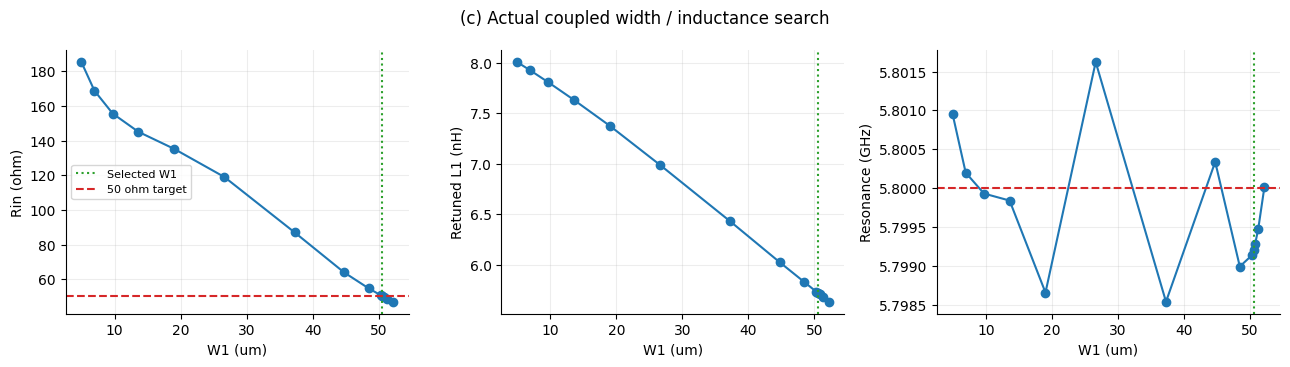

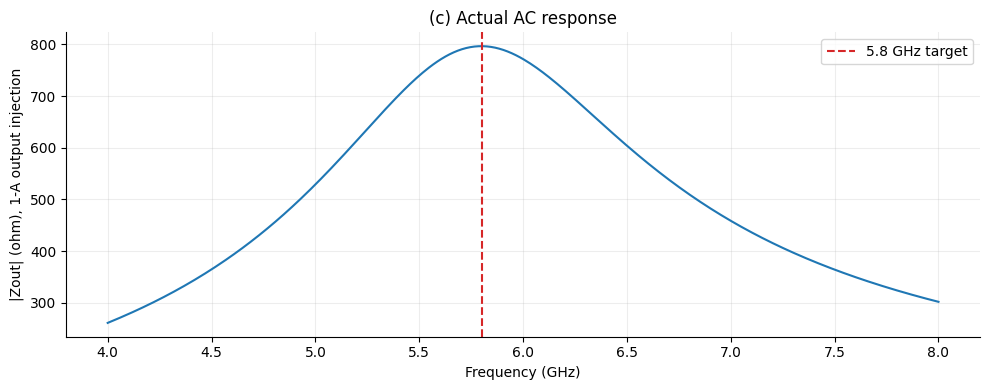

In [7]:
if EXECUTION_MODE == "review":
    show_part("c")